# KG Water Intelligence — Day 7: a leakage-safe feature dataset

**Goal:** a reproducible dataset for forecasting the soil-moisture anomaly **3–7 days ahead**, with chronological splits and a persistence baseline evaluated on identical dates.

**Plan for this notebook**
1. Confirm the Day 6 deliverables and that the target is **reproducible** from its documented inputs.
2. Find and fix a **leakage problem in Day 6** (the baseline "normal" used future years).
3. Build the feature dataset (`scripts/build_features.py`) and **audit leakage with automated tests**.
4. Define **chronological splits** and check each has enough positive labels (rule fixed *before* looking at results).
5. Evaluate the **persistence baseline** on the held-out years and document quality and limitations.

In [1]:
import sys, warnings; sys.path.insert(0, "../scripts"); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
import build_features as bf
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
FIG = "reports/figures/"; SURF, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
COL = {"train": "#7d8aa0", "val": "#2a78d6", "test": "#e5483c"}
def style(ax):
    ax.set_facecolor(SURF); [ax.spines[s].set_visible(False) for s in ("top", "right", "left")]; ax.spines["bottom"].set_color(GRID); ax.tick_params(colors=INK2, length=0, labelsize=10); ax.grid(axis="y", color=GRID, lw=.8); ax.set_axisbelow(True)
import os; os.chdir("..")                                    # repository root, so the pipeline paths work
d = bf.load_grid(); print(f"{len(d):,} rows, {d.cell_id.nunique()} cells, {d.date.min().date()} to {d.date.max().date()}")

76,680 rows, 30 cells, 2018-01-02 to 2024-12-31


## 1. Day 6 deliverables and reproducibility of the target

In [2]:
import subprocess
print(subprocess.run(["git", "log", "--oneline", "-3"], capture_output=True, text=True).stdout)
need = ["docs/water_stress_target.md", "notebooks/06_water_stress_target.ipynb", "data/processed/soil_moisture_anomaly_loyo.csv.gz"] + [f"reports/figures/target_{n}.png" for n in ("seasonal_cycle", "timeseries", "yearly", "vs_ndvi")]
print("Day 6 files present:", all(os.path.exists(p) for p in need), "| tracked in git:", all(subprocess.run(["git", "ls-files", "--error-unmatch", p], capture_output=True).returncode == 0 for p in need))

e18c507 Day 6: provisional water-stress target (soil-moisture anomaly), analysis notebook, figures and target definition
38411e9 Day 5: exploratory analysis of weather vs NDVI (notebook, figures, findings and limitations)
278b94c Day 4: first structured dataset (weather + NDVI + cropland on the ERA5-Land grid), audit and coverage summary

Day 6 files present: True | tracked in git: True


In [3]:
# Re-compute the Day 6 anomaly from the documented inputs (leave-one-year-out normal, +-15 days) and compare with the saved CSV.
YEARS = sorted(d.date.dt.year.unique())
def loyo_z(cell_df, col, win=15):
    doy_ = np.minimum(cell_df.date.dt.dayofyear.values, 365); yr = cell_df.date.dt.year.values; M = np.full((len(YEARS), 365), np.nan)
    for i, y in enumerate(YEARS): m = yr == y; M[i, doy_[m] - 1] = cell_df[col].values[m]
    k = np.ones(2 * win + 1); circ = lambda A: np.apply_along_axis(lambda r: np.convolve(r, k, mode="valid"), 1, np.concatenate([A[:, -win:], A, A[:, :win]], axis=1))
    V = ~np.isnan(M); S, Q, Nn = circ(np.nan_to_num(M)), circ(np.nan_to_num(M) ** 2), circ(V.astype(float))
    mu = (S.sum(0) - S) / (Nn.sum(0) - Nn); sd = np.maximum(np.sqrt(np.maximum((Q.sum(0) - Q) / (Nn.sum(0) - Nn) - mu ** 2, 1e-6)), 0.01)
    yi = np.searchsorted(YEARS, yr); return (cell_df[col].values - mu[yi, doy_ - 1]) / sd[yi, doy_ - 1]
d["z6"] = np.nan
for c, g_ in d.groupby("cell_id"): d.loc[g_.index, "z6"] = loyo_z(g_, "soil_moisture_l2_m3m3")
saved = pd.read_csv("data/processed/soil_moisture_anomaly_loyo.csv.gz", parse_dates=["date"])[["date", "cell_id", "z_l2"]]; m6 = d[["date", "cell_id", "z6"]].merge(saved, on=["date", "cell_id"])
diff = (m6.z6 - m6.z_l2).abs().max(); print(f"Day 6 anomaly recomputed for {len(m6):,} cell-days; max |difference| vs the saved file = {diff:.4f}  ->  {'REPRODUCIBLE' if diff < 6e-4 else 'MISMATCH'} (file is rounded to 3 decimals)")

Day 6 anomaly recomputed for 76,680 cell-days; max |difference| vs the saved file = 0.0005  ->  REPRODUCIBLE (file is rounded to 3 decimals)


## 2. A leakage problem in Day 6
Day 6 computed each year's "normal" from the **other** years (leave-one-year-out). That is fine for describing the data, but for forecasting it lets a test year be judged against a normal that contains **future years** (and a training year against the test year). My own doc said that for modelling the normal must come from the **training years only**. Day 7 therefore uses a **fixed normal from 2018–2022** (`soil_moisture_normal_train2018_2022.csv`) applied to every year.

## 3. Build the dataset

In [4]:
f, q = bf.build(d)
print(f"{q['rows']:,} rows × {f.shape[1]} columns | positive-label rate {q['positive_rate_pct']} % | outside growing season (excluded): {q['excluded_outside_growing_season']:,} | excluded for missing history/label: {q['excluded_missing_history_or_label']}")
print("rows per forecast date:", f.groupby("forecast_date").size().unique(), "(= the 30 cells)")
print("duplicates (date, cell):", int(f.duplicated(["forecast_date", "cell_id"]).sum()))
f.loc[f.forecast_date == "2024-06-15"].head(3).T.round(3)

44,940 rows × 28 columns | positive-label rate 10.11 % | outside growing season (excluded): 31,740 | excluded for missing history/label: 0
rows per forecast date: [30] (= the 30 cells)
duplicates (date, cell): 0


,40770,40771,40772
forecast_date,2024-06-15 00:00:00,2024-06-15 00:00:00,2024-06-15 00:00:00
cell_id,9,10,11
latitude,43.2,43.2,43.2
longitude,74.1,74.2,74.3
cropland_km2,3.64,54.03,55.21
doy_sin,0.263665,0.263665,0.263665
doy_cos,-0.964614,-0.964614,-0.964614
sm_l2_t,0.1807,0.1741,0.1679
z_l1_t,-0.26453,-0.327644,-0.396638
z_l2_t,1.87326,1.529677,1.110258


In [5]:
pd.read_csv("data/processed/water_stress_feature_definitions.csv")

,feature(s),group,definition,observation window,source
0,"latitude, longitude, cropland_km2",static,cell centre and cropland area,constant,Day 4 grid
1,"doy_sin, doy_cos",calendar,sin/cos of day of year of t,date t,calendar
2,sm_l2_t,soil,ERA5-Land volumetric soil water 7-28 cm on day...,day t,ERA5-Land swvl2
3,"z_l1_t, z_l2_t",soil,"anomaly z of layers 0-7 / 7-28 cm on day t, vs...",day t,ERA5-Land + normals 2018-2022
4,"z_l2_mean3, z_l2_mean7",soil,mean of z_l2 over days t-2..t and t-6..t,days t-6..t,ERA5-Land + normals
5,z_l2_delta3,soil,z_l2 on day t minus z_l2 on day t-3,"days t-3, t",ERA5-Land + normals
6,temp_mean_7d,weather,mean 2 m air temperature over days t-6..t (degC),days t-6..t,ERA5-Land
7,temp_max_7d,weather,maximum of the daily maximum temperature over ...,days t-6..t,ERA5-Land
8,"precip_sum_7d, precip_sum_14d",weather,total precipitation over days t-6..t and t-13....,days t-13..t,ERA5-Land
9,days_since_rain,weather,days since the last day with >= 1 mm precipita...,days <= t,ERA5-Land


In [6]:
# missing values by split (only NDVI can be missing: it is never interpolated)
miss = f.groupby("split")[["ndvi_last", "ndvi_age_days", "ndvi_valid_frac_last"]].apply(lambda g: g.isna().mean() * 100).round(1); miss["rows"] = f.groupby("split").size(); miss

,ndvi_last,ndvi_age_days,ndvi_valid_frac_last,rows
split,,,,
test,17.0,17.0,17.0,6420
train,100.0,100.0,100.0,32100
val,20.5,20.5,20.5,6420


**NDVI cannot be used for training.** NDVI exists only from April 2023, so the whole training set (2018–2022) has no NDVI feature; a model using it would learn from 2023 alone, which is also the validation year. A first model must therefore use soil-moisture, weather and calendar features only; NDVI is kept in the table for later.

## 4. Leakage audit — automated tests
A feature is *allowed* only if it can be computed from data available at forecast time *t*. The strongest test: **delete all data after *t* and recompute the features** — they must come out identical.

In [7]:
normals = bf.normals_table(d); results = []
def record(name, ok, detail): results.append({"test": name, "result": "PASS" if ok else "FAIL", "detail": detail}); print(("PASS  " if ok else "FAIL  ") + name + " — " + detail)

# T1: truncation test - recompute features from raw data truncated at t, for 240 random rows (80 per split)
rng = np.random.default_rng(7); samp = pd.concat([f[f.split == s].sample(80, random_state=7) for s in ("train", "val", "test")]); bad = 0; checked = 0
obs_all = d.loc[d.ndvi.notna(), ["cell_id", "date", "ndvi", "ndvi_valid_frac"]]
for r in samp.itertuples():
    g = d[(d.cell_id == r.cell_id) & (d.date <= r.forecast_date)]; nt = normals[normals.cell_id == r.cell_id].set_index("doy").sort_index()
    ft = bf.add_ndvi(bf.cell_features(g, nt), obs_all[(obs_all.cell_id == r.cell_id) & (obs_all.date <= r.forecast_date)]).iloc[-1]
    for c in bf.FEATURES:
        a, b = getattr(r, c), ft[c]
        if not ((pd.isna(a) and pd.isna(b)) or np.isclose(a, b, atol=1e-9)): bad += 1
    checked += len(bf.FEATURES)
    assert pd.isna(ft["label_dry_t3_t7"]), "label must not be computable without future data"
record("T1 features unchanged when all data after t is deleted", bad == 0, f"{len(samp)} rows × {len(bf.FEATURES)} features compared, {bad} differences; label is empty without future data")

# T2: baseline isolation - changing 2023/2024 raw soil moisture must not change the normal or any training-year row
d2 = d.copy(); m_ = d2.date.dt.year >= 2023; d2.loc[m_, ["soil_moisture_l1_m3m3", "soil_moisture_l2_m3m3"]] += 0.07
n2 = bf.normals_table(d2); f2, _ = bf.build(d2, n2)
same_norm = np.allclose(normals[["mu_l1", "sd_l1", "mu_l2", "sd_l2"]].values, n2[["mu_l1", "sd_l1", "mu_l2", "sd_l2"]].values)
cols = bf.FEATURES + ["z_l2_future_mean_t3_t7", "label_dry_t3_t7"]; tr1, tr2 = f[f.split == "train"].reset_index(drop=True), f2[f2.split == "train"].reset_index(drop=True)
same_train = np.allclose(tr1[cols].fillna(-999).values, tr2[cols].fillna(-999).values, atol=1e-9); changed_test = not np.allclose(f[f.split == "test"].z_l2_t.values, f2[f2.split == "test"].z_l2_t.values)
record("T2 normal and training rows do not depend on 2023/2024 data", same_norm and same_train and changed_test, f"normal identical: {same_norm}; all training features+labels identical: {same_train}; (sanity) test rows do change: {changed_test}")

# T3: NDVI timing
nd = f.dropna(subset=["ndvi_obs_date"]); lag = (nd.forecast_date - nd.ndvi_obs_date).dt.days
record("T3 NDVI is at least 2 and at most 21 days old, never from the future", bool(lag.min() >= bf.NDVI_LATENCY and lag.max() <= bf.NDVI_MAX_AGE), f"age range {lag.min()}–{lag.max()} days over {len(nd):,} rows with NDVI; {int((nd.ndvi_obs_date > nd.forecast_date).sum())} observations after t")

# T4: label window strictly in the future and disjoint from the feature windows
gap = (f.label_window_start - f.forecast_date).dt.days; span = (f.label_window_end - f.label_window_start).dt.days
record("T4 label window = days t+3..t+7 (gap of 3 days after t, 4-day span)", bool(gap.eq(3).all() and span.eq(4).all()), f"gap values {sorted(gap.unique())}, span values {sorted(span.unique())}")

# T5: chronological splits do not overlap in time, label windows do not cross split boundaries
last_tr, first_va, last_va, first_te = f[f.split == "train"].label_window_end.max(), f[f.split == "val"].forecast_date.min(), f[f.split == "val"].label_window_end.max(), f[f.split == "test"].forecast_date.min()
record("T5 splits are chronological; no label window of one split reaches the next", bool(last_tr < first_va and last_va < first_te), f"last train label day {last_tr.date()} < first val date {first_va.date()}; last val label day {last_va.date()} < first test date {first_te.date()}")

# T6: the persistence baseline reads only z_l2_t (and the label): shuffling every other column changes nothing
v = f[f.split == "val"].copy(); a0 = bf.persistence_metrics(v)["AUC"]; sh = v.copy(); [sh.__setitem__(c, np.random.default_rng(1).permutation(sh[c].values)) for c in bf.FEATURES if c != "z_l2_t"]
record("T6 persistence uses only information at t (z_l2_t)", np.isclose(a0, bf.persistence_metrics(sh)["AUC"]), f"validation AUC {a0:.4f} unchanged after shuffling all other feature columns")
pd.DataFrame(results)

PASS  T1 features unchanged when all data after t is deleted — 240 rows × 19 features compared, 0 differences; label is empty without future data
PASS  T2 normal and training rows do not depend on 2023/2024 data — normal identical: True; all training features+labels identical: True; (sanity) test rows do change: True
PASS  T3 NDVI is at least 2 and at most 21 days old, never from the future — age range 2–21 days over 10,432 rows with NDVI; 0 observations after t
PASS  T4 label window = days t+3..t+7 (gap of 3 days after t, 4-day span) — gap values [np.int64(3)], span values [np.int64(4)]
PASS  T5 splits are chronological; no label window of one split reaches the next — last train label day 2022-11-07 < first val date 2023-04-01; last val label day 2023-11-07 < first test date 2024-04-01


PASS  T6 persistence uses only information at t (z_l2_t) — validation AUC 0.9391 unchanged after shuffling all other feature columns


,test,result,detail
0,T1 features unchanged when all data after t is...,PASS,"240 rows × 19 features compared, 0 differences..."
1,T2 normal and training rows do not depend on 2...,PASS,normal identical: True; all training features+...
2,"T3 NDVI is at least 2 and at most 21 days old,...",PASS,"age range 2–21 days over 10,432 rows with NDVI..."
3,T4 label window = days t+3..t+7 (gap of 3 days...,PASS,"gap values [np.int64(3)], span values [np.int6..."
4,T5 splits are chronological; no label window o...,PASS,last train label day 2022-11-07 < first val da...
5,T6 persistence uses only information at t (z_l...,PASS,validation AUC 0.9391 unchanged after shufflin...


## 5. Chronological splits and whether each has enough positives
**Rule fixed before looking at results:** a year is *adequate* for evaluation if it has **≥ 200 positive cell-days and ≥ 3 independent positive episodes** (an episode = a run of consecutive forecast dates on which ≥ 10 % of the cells are positive). Cell-days from the same dry spell are strongly dependent, so episodes matter more than row counts.

In [8]:
st = bf.split_table(f); st

,year,split,rows,positive_cell_days,positive_rate_pct,positive_episodes,days_with_>=10%_cells_positive,adequate
0,2018,train,6420,137,2.13,4,19,False
1,2019,train,6420,693,10.79,5,65,True
2,2020,train,6420,511,7.96,5,47,True
3,2021,train,6420,1135,17.68,8,113,True
4,2022,train,6420,431,6.71,6,48,True
5,2023,val,6420,1523,23.72,3,115,True
6,2024,test,6420,114,1.78,1,17,False


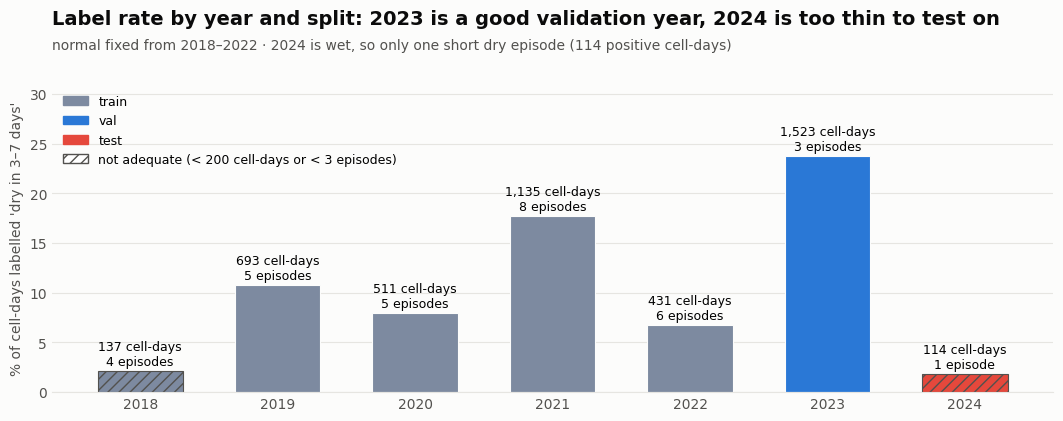

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.6)); fig.subplots_adjust(left=.07, right=.98, top=.8, bottom=.13); fig.set_facecolor(SURF)
for i, r in st.iterrows(): ax.bar(str(r.year), r.positive_rate_pct, color=COL[r.split], width=.62, hatch="" if r.adequate else "///", edgecolor=SURF if r.adequate else INK2, lw=.8); ax.text(i, r.positive_rate_pct + .6, f"{r.positive_cell_days:,} cell-days\n{r.positive_episodes} episode{'s' if r.positive_episodes != 1 else ''}", ha="center", fontsize=9)
style(ax); ax.set_ylabel("% of cell-days labelled 'dry in 3–7 days'", color=INK2); ax.set_ylim(0, 31)
from matplotlib.patches import Patch; ax.legend(handles=[Patch(color=COL[k], label=k) for k in COL] + [Patch(facecolor="white", edgecolor=INK2, hatch="///", label="not adequate (< 200 cell-days or < 3 episodes)")], frameon=False, fontsize=9, loc="upper left")
fig.text(.07, .93, "Label rate by year and split: 2023 is a good validation year, 2024 is too thin to test on", fontsize=14, fontweight="bold", color=INK)
fig.text(.07, .875, "normal fixed from 2018–2022 · 2024 is wet, so only one short dry episode (114 positive cell-days)", fontsize=10, color=INK2)
fig.savefig(FIG + "features_split_label_rates.png", dpi=170); plt.show()

**Decision (documented, not tuned):** the planned split is kept — **train 2018–2022, validation 2023, test 2024**. 2023 passes the adequacy rule. **2024 does not** (114 positive cell-days from one episode), so its results are reported but must be read as *descriptive*, not as reliable evidence. I do **not** move years between splits to obtain a more comfortable test set.

## 6. Persistence baseline on the held-out years

In [10]:
rows = []
for s in ("train", "val", "test"):
    g = f[f.split == s]; m = bf.persistence_metrics(g)
    lo, hi = bf.bootstrap_auc(g) if s != "train" else (np.nan, np.nan); rows.append({"split": s, **m, "AUC 95% CI": f"{lo:.2f}–{hi:.2f}" if lo == lo else "(in-sample)"})
ev = pd.DataFrame(rows).set_index("split"); ev["adequate"] = [bool(st[st.split == s].adequate.all()) if s != "train" else None for s in ev.index]
ev[["rows", "base_rate_%", "AUC", "AUC 95% CI", "precision", "recall", "F1", "lift_vs_base", "adequate"]].round(3)

,rows,base_rate_%,AUC,AUC 95% CI,precision,recall,F1,lift_vs_base,adequate
split,,,,,,,,,
train,32100,9.06,0.878,(in-sample),0.535,0.595,0.563,5.907,None
val,6420,23.72,0.939,0.89–0.97,0.762,0.821,0.790,3.213,True
test,6420,1.78,0.961,0.93–1.00,0.559,0.623,0.589,31.484,False


In [11]:
# per year, and compared with Day 6 (leave-one-year-out normal = uses future years)
h6 = d[["cell_id", "date", "z6"]].copy(); parts = []
for c, g_ in h6.groupby("cell_id"):
    s = g_.set_index("date").z6; fut = pd.concat([s.shift(-k) for k in range(3, 8)], axis=1).mean(axis=1); parts.append(pd.DataFrame({"cell_id": c, "forecast_date": s.index, "z_now6": s.values, "lab6": (fut <= -1).astype(float).where(fut.notna())}))
h6 = pd.concat(parts); h6 = h6[h6.forecast_date.dt.month.between(4, 10)].dropna(); h6["year"] = h6.forecast_date.dt.year
rows = []
for y, g in f.groupby("year"):
    g6 = h6[h6.year == y]; rows.append({"year": int(y), "split": bf.split_of(int(y)), "AUC, Day 7 (fixed 2018–22 normal)": bf.persistence_metrics(g)["AUC"], "AUC, Day 6 (leave-one-year-out normal)": bf.auc(-g6.z_now6.values, g6.lab6.values)})
by_year = pd.DataFrame(rows).set_index("year").round(3); print("pooled Day 6 AUC (all years):", round(bf.auc(-h6.z_now6.values, h6.lab6.values), 3), "| pooled Day 7 AUC (all years):", round(bf.auc(-f.z_l2_t.values, f.label_dry_t3_t7.values), 3)); by_year

pooled Day 6 AUC (all years): 0.927 | pooled Day 7 AUC (all years): 0.912


,split,"AUC, Day 7 (fixed 2018–22 normal)","AUC, Day 6 (leave-one-year-out normal)"
year,,,
2018,train,0.815,0.868
2019,train,0.920,0.945
2020,train,0.872,0.927
2021,train,0.862,0.874
2022,train,0.823,0.869
2023,val,0.939,0.940
2024,test,0.961,0.964


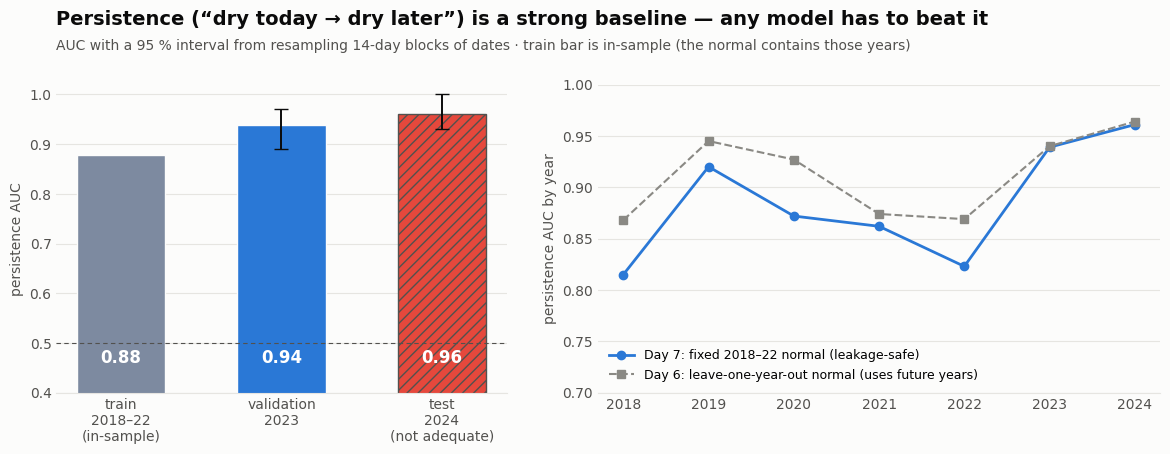

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.25]}); fig.subplots_adjust(left=.06, right=.98, top=.8, bottom=.13, wspace=.18); fig.set_facecolor(SURF)
for i, s in enumerate(("train", "val", "test")):
    a = ev.loc[s, "AUC"]; ax[0].bar(i, a, color=COL[s], width=.55, hatch="" if s != "test" else "///", edgecolor=SURF if s != "test" else INK2)
    if s != "train": lo, hi = [float(x) for x in ev.loc[s, "AUC 95% CI"].split("–")]; ax[0].errorbar(i, a, yerr=[[a - lo], [hi - a]], color=INK, capsize=5, lw=1.4)
    ax[0].text(i, .46, f"{a:.2f}", ha="center", color="white", fontsize=12, fontweight="bold")
style(ax[0]); ax[0].set_xticks(range(3)); ax[0].set_xticklabels(["train\n2018–22\n(in-sample)", "validation\n2023", "test\n2024\n(not adequate)"]); ax[0].set_ylim(.4, 1.02); ax[0].axhline(.5, color=INK2, lw=.8, ls=(0, (4, 3))); ax[0].set_ylabel("persistence AUC", color=INK2)
x = by_year.index.astype(str); ax[1].plot(x, by_year["AUC, Day 7 (fixed 2018–22 normal)"], "o-", color="#2a78d6", lw=2, label="Day 7: fixed 2018–22 normal (leakage-safe)"); ax[1].plot(x, by_year["AUC, Day 6 (leave-one-year-out normal)"], "s--", color="#8a8984", lw=1.5, label="Day 6: leave-one-year-out normal (uses future years)")
style(ax[1]); ax[1].set_ylim(.7, 1.0); ax[1].legend(frameon=False, fontsize=9, loc="lower left"); ax[1].set_ylabel("persistence AUC by year", color=INK2)
fig.text(.06, .93, "Persistence (“dry today → dry later”) is a strong baseline — any model has to beat it", fontsize=14, fontweight="bold", color=INK)
fig.text(.06, .875, "AUC with a 95 % interval from resampling 14-day blocks of dates · train bar is in-sample (the normal contains those years)", fontsize=10, color=INK2)
fig.savefig(FIG + "features_persistence_auc.png", dpi=170); plt.show()

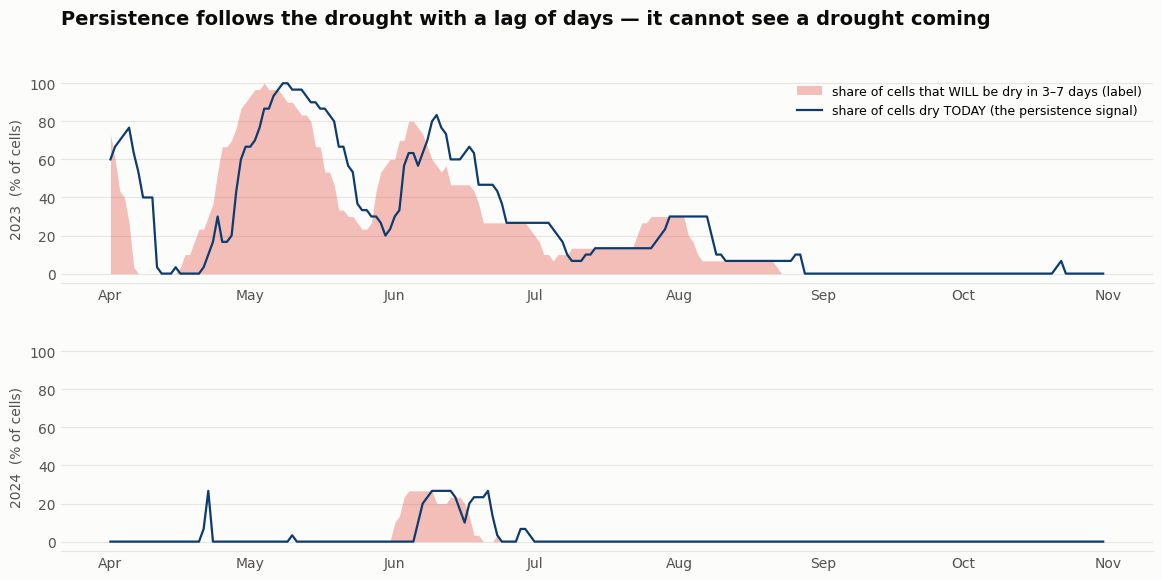

In [13]:
# what persistence does in time: share of cells dry today vs share that will be dry in 3-7 days (validation and test years)
fig, ax = plt.subplots(2, 1, figsize=(12, 6.2), sharey=True); fig.subplots_adjust(left=.07, right=.98, top=.86, bottom=.09, hspace=.28); fig.set_facecolor(SURF)
for a, y in zip(ax, (2023, 2024)):
    g = f[f.year == y]; now = g.groupby("forecast_date").apply(lambda x: (x.z_l2_t <= -1).mean() * 100); fut = g.groupby("forecast_date").label_dry_t3_t7.mean() * 100
    a.fill_between(fut.index, fut.values, color="#e5483c", alpha=.35, lw=0, label="share of cells that WILL be dry in 3–7 days (label)"); a.plot(now.index, now.values, color="#0b3b6f", lw=1.6, label="share of cells dry TODAY (the persistence signal)")
    style(a); a.set_ylabel(f"{y}  (% of cells)", color=INK2); a.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax[0].legend(frameon=False, fontsize=9, loc="upper right"); fig.text(.07, .94, "Persistence follows the drought with a lag of days — it cannot see a drought coming", fontsize=14, fontweight="bold", color=INK)
fig.savefig(FIG + "features_persistence_timeline.png", dpi=170); plt.show()

## 7. Dataset quality and limitations
- **Quality:** 44,940 rows (30 cells × 214 growing-season dates × 7 years), no duplicates, **no missing values except NDVI**, nothing excluded beyond the dormant season (Nov–Mar).
- **Positive rate:** 10.1 % overall; by year 2–24 %. Rows within a dry spell are strongly dependent, so the *effective* sample size is the number of episodes (1–8 per year), not the row count.
- **2024 cannot serve as a reliable test.** It is a wet year with one short dry episode. Results on it are reported but not interpreted as evidence; the plan's split is kept.
- **NDVI is absent from the training years**, so it cannot be used in a model trained on 2018–2022.
- **The target is model-made** (ERA5-Land soil moisture from the same rain and temperature that appear as features), so a model that predicts it from weather is partly re-learning the land model — not independent evidence of stress.
- **Persistence is strong because soil moisture is slow-moving:** what a model must add is *anticipating* onset and recovery from rain and temperature.
- **The Day 6 persistence AUC (0.93) used a normal containing future years.** With the leakage-safe normal the pooled value is shown above.

Outputs: `data/processed/water_stress_features.parquet`, `water_stress_feature_definitions.csv`, `water_stress_splits.csv`, `soil_moisture_normal_train2018_2022.csv`, `reports/feature_dataset_quality.json`; protocol in `docs/evaluation_protocol.md`.